# 0. Cadrage

**Contexte** : Les données nettoyées contiennent 4052 lignes (clients) et 7 colonnes (fonctionnalités) incluant un `Churn(Resiliation)`.

**Objectif** : Analyser le fichier nettoyé précedemment.

**Variables explicatives** :  6 variables

**Cible** : `« Churn »`  

**Démarche** : EDA

# 1. Librairies

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "data"
CLEAN_DIR = DATA_DIR / "clean"

CLEAN_FILE = CLEAN_DIR / "churn_clean.parquet"

In [3]:
df = pd.read_parquet(CLEAN_FILE)
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (4052, 7)


,age,sexe,anciennete_mois,montant_mensuel_fcfa,nb_reclamations,type_contrat,churn
0,43.0,femme,53.0,18800.0,2,mensuel,0
1,24.0,femme,28.0,7200.0,0,annuel,0
2,63.0,homme,51.0,6600.0,2,mensuel,0
3,20.0,femme,13.0,16600.0,0,mensuel,0
4,52.0,femme,67.0,16000.0,3,mensuel,0


# 2. Visualisations

#### Repartition de la variable cible

       count    pct
churn              
0       3204  0.791
1        848  0.209


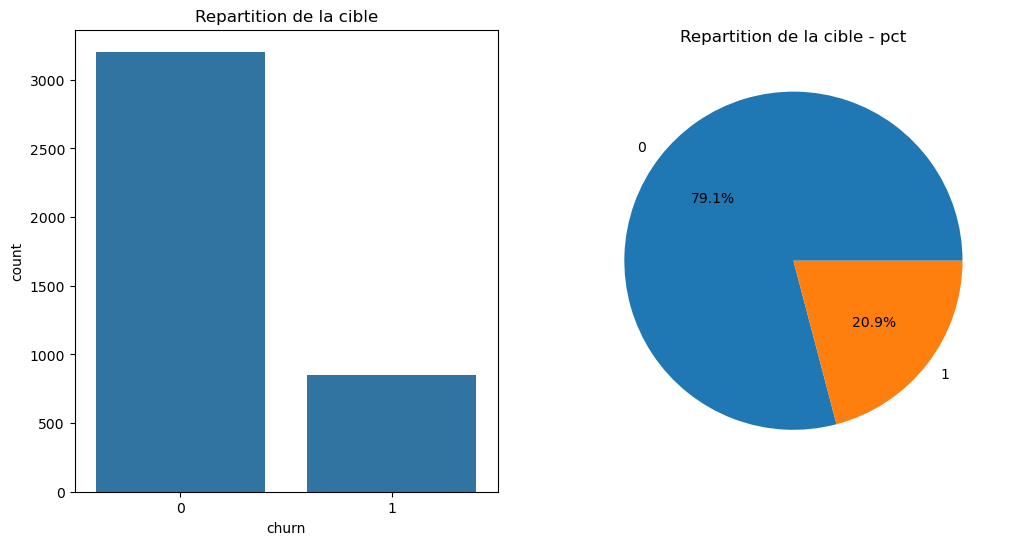

In [4]:
cible = pd.DataFrame({
    'count' : df['churn'].value_counts(),
    'pct' : df['churn'].value_counts(normalize=True).round(3)
})

print(cible)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
sns.countplot(x='churn', data=df)
plt.title("Repartition de la cible")

plt.subplot(1,2,2)
plt.pie(x=cible['pct'], labels=cible.index, autopct='%1.1f%%')
plt.title("Repartition de la cible - pct")

plt.show()

> **Classes desequilibrées** : **Influence sur le choix des metriques et de la strategie de decoupage**.

#### Pairplot

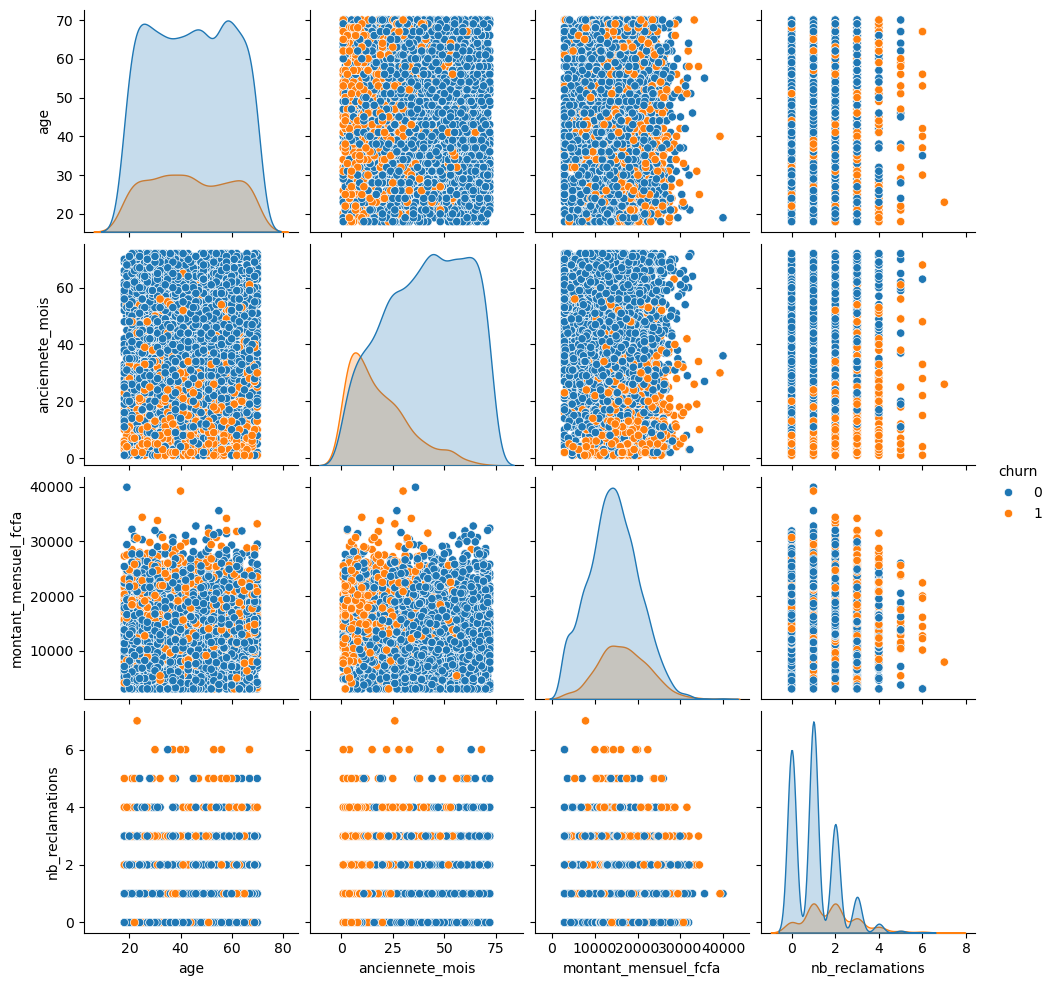

In [16]:
sns.pairplot(data=df, hue='churn')
plt.show()

**Lecture rapide** :
 - **Le `montant_mensuel` et l'`anciennete_mois` permettent d'avoir une repartition plus claire du churn (à vérifier)**.
 - **L'`age` et l'`anciennete_mois` permettent d'avoir une repartition plus claire du churn (à vérifier)**.

#### Verification precedente

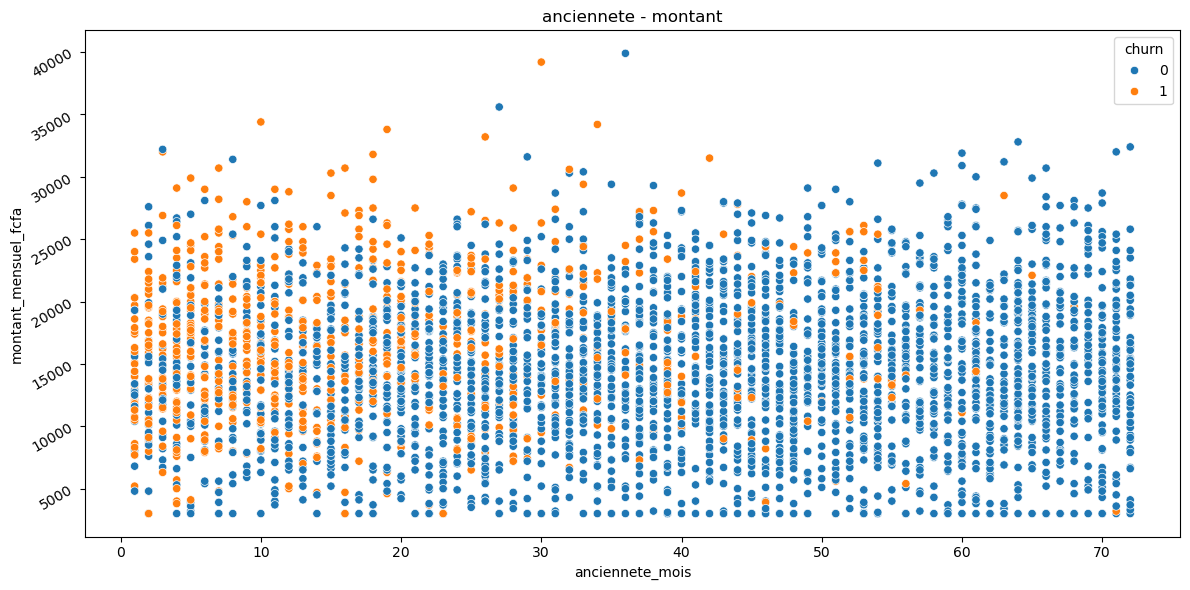

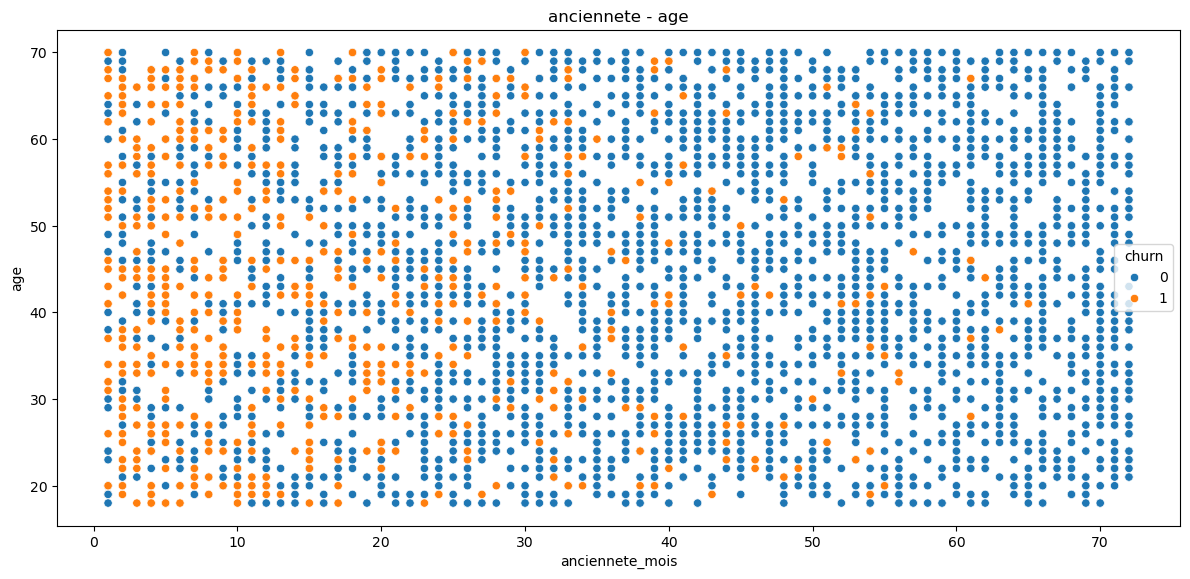

In [6]:
plt.figure(figsize=(12,6))
plt.subplot(1,1,1)
sns.scatterplot(x='anciennete_mois', y='montant_mensuel_fcfa', data=df, hue='churn')
plt.yticks(rotation=30)
plt.title("anciennete - montant")
plt.tight_layout()
#plt.show()

plt.figure(figsize=(12,11))
plt.subplot(2,1,1)
sns.scatterplot(x='anciennete_mois', y='age', data=df, hue='churn')
plt.title("anciennete - age")
plt.tight_layout()
plt.show()

**Idée** :
> **`age`, `montant_mensuel`, `anciennete_mois` peuvent constituer nos features phares**.

#### Crosstab

In [7]:
f = lambda x : "Reste" if x==0 else "Part"

X = df.copy()

X['churn_nom'] = X['churn'].apply(f)
X.churn_nom.value_counts()

churn_nom
Reste    3204
Part      848
Name: count, dtype: int64

In [8]:
nom_cols = X.select_dtypes("object").columns.drop('churn_nom')

for c in nom_cols :
    print(f"{c} ----- churn_nom")
    print(pd.crosstab(X[c],X['churn_nom']))
    print()

sexe ----- churn_nom
churn_nom  Part  Reste
sexe                  
femme       422   1567
homme       426   1637

type_contrat ----- churn_nom
churn_nom     Part  Reste
type_contrat             
annuel         136   1072
bisannuel       55    529
mensuel        657   1603



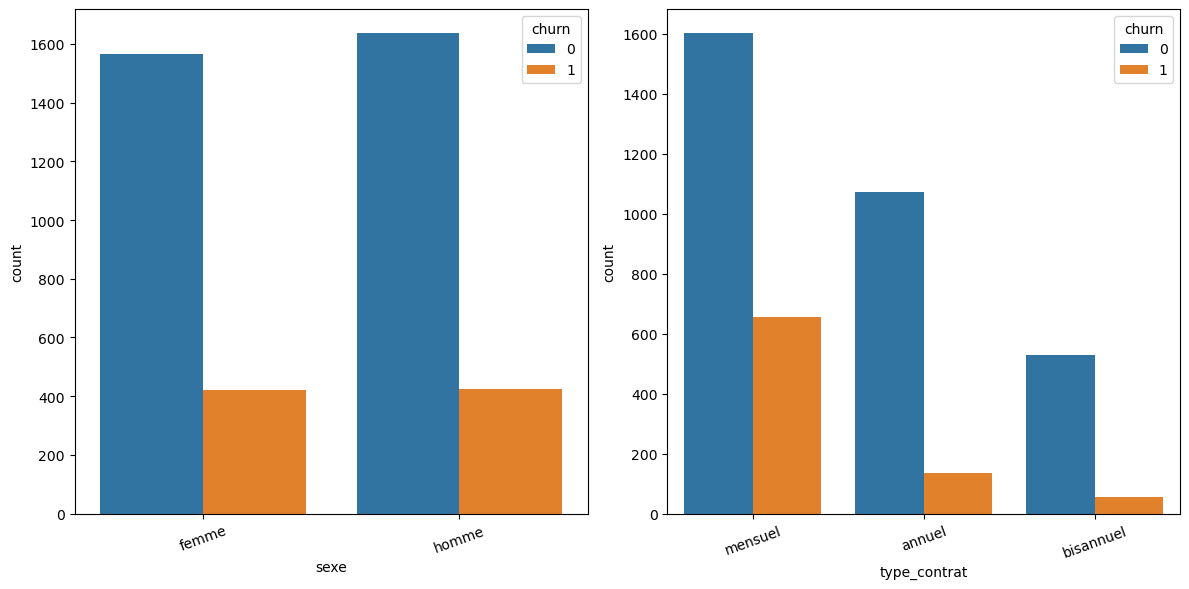

In [9]:
cat_cols = df.select_dtypes("object").columns

plt.figure(figsize=(12,6))
for i, col in enumerate(cat_cols):
    plt.subplot(1,2,i+1)
    sns.countplot(x=col, data=df, hue='churn')
    plt.xticks(rotation=20)
    plt.tight_layout()
plt.show()

**Lecture rapide** :
 - Dans l'ordre des `type_contrat`, les clients de la categorie `mensuel` ont tendance à **partir** en majorité.
 - Pas de différence entre `sexe`.

#### Histogrammes

In [10]:
num_vals = df.select_dtypes("number").columns.drop('churn')
num_vals

Index(['age', 'anciennete_mois', 'montant_mensuel_fcfa', 'nb_reclamations'], dtype='object')

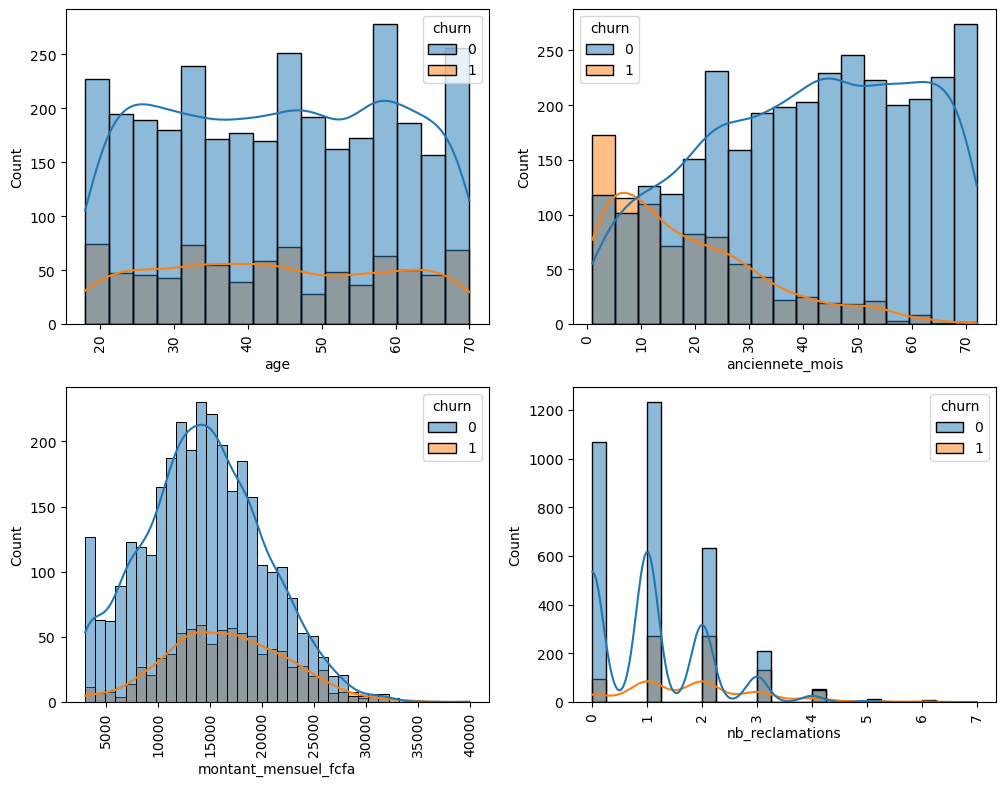

In [11]:
plt.figure(figsize=(12,9))

for i, col in enumerate(num_vals):
    plt.subplot(2, 2, i+1)
    sns.histplot(x=col, data=df, hue='churn', kde=True)
    plt.xticks(rotation=90)
    plt.tight_layout

plt.show()

#### Boxplots

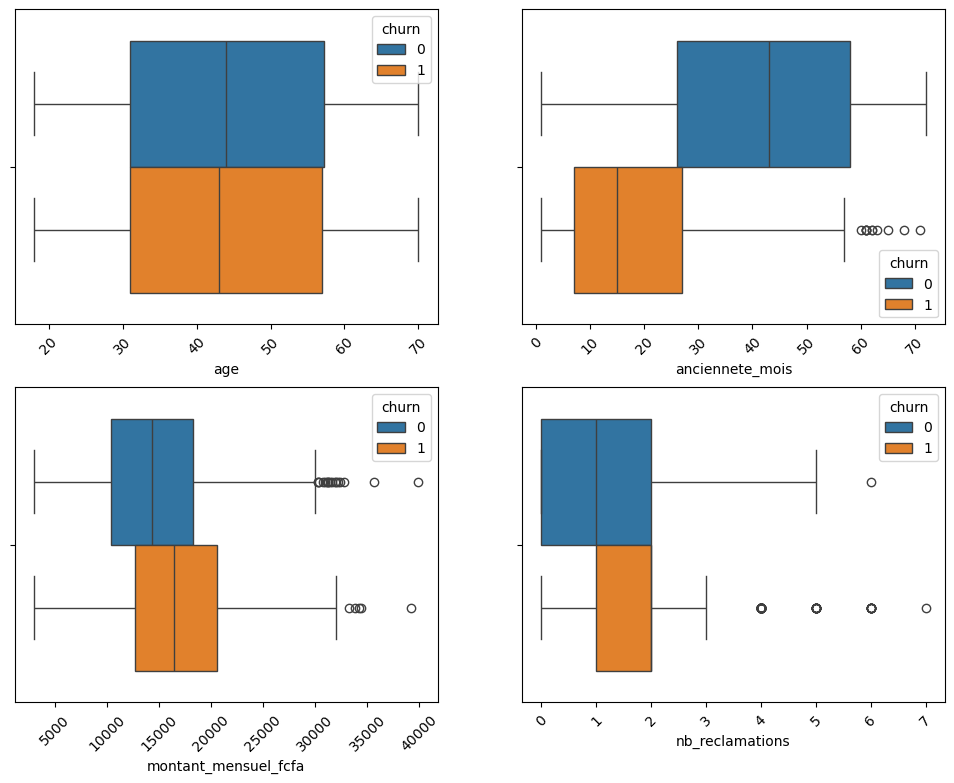

In [12]:
plt.figure(figsize=(12,9))

for i, col in enumerate(num_vals):
    plt.subplot(2, 2, i+1)
    sns.boxplot(x=col, data=df, hue='churn')
    plt.xticks(rotation=45)
    plt.tight_layout

plt.show()

#### Correlations

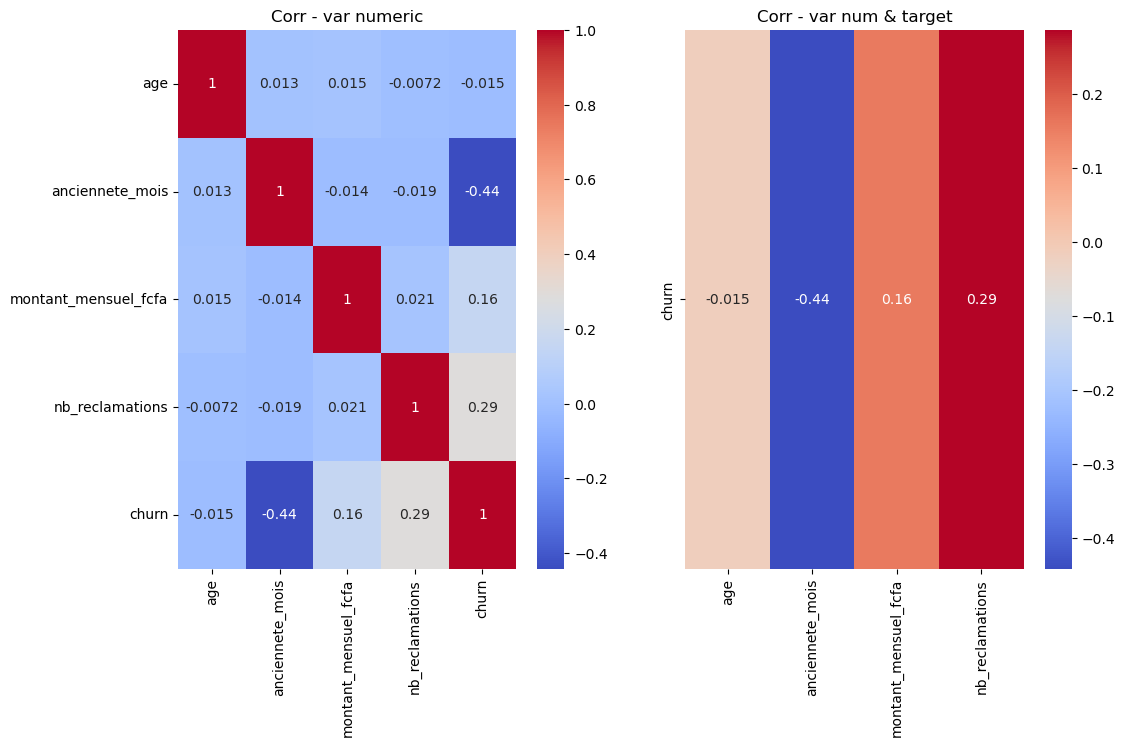

In [13]:
plt.figure(figsize=(12,7))

plt.subplot(1,2,1)
corr_num = df.corr(numeric_only=True)
sns.heatmap(corr_num,annot=True, cmap="coolwarm")
plt.title("Corr - var numeric")


plt.subplot(1,2,2)
corr_cible = df.corr(numeric_only=True)['churn'].drop('churn')
sns.heatmap(corr_cible.to_frame().T,  annot=True, cmap="coolwarm")
plt.title("Corr - var num & target")

plt.tight_layout
plt.show()